<a href="https://colab.research.google.com/github/pdf1802/f1-data-science/blob/main/notebooks/driver_style_fingerprinting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 3 — Driver Style Fingerprinting

**Goal:** Use telemetry data to extract each driver's style signature
and cluster them using unsupervised ML.

**Approach:** We use qualifying laps — no traffic, no strategy,
maximum effort from every driver. Pure style signal.

**Pipeline:** Load → Resample to distance grid → Engineer features
→ Aggregate per driver → Scale → PCA → K-Means → UMAP → Visualize

> **V3 (Nov 2026) — the right races, re-run.** The V2 run asked FastF1 for `'Great Britain'`, and FastF1's fuzzy
> event matching returned the **Austrian GP** for 2024 and 2025: two of the twenty sessions were the wrong race,
> labelled British. V3 asks for **full event names and asserts** the event that loaded. The British sessions are not
> in the local FastF1 cache (and can't be downloaded: the archive answers 401 since Oct 2026), so V3 runs on the
> other **18 sessions** — correctly labelled. Also: the resampling and feature functions are now the shared ones
> (`tools/shared.py`, used by the dashboard), `pick_driver` → `pick_drivers`, driver codes instead of car numbers,
> matplotlib plots (they render on GitHub; Plotly outputs don't), and cluster names derived from the data instead of
> typed by hand — a re-run can renumber clusters.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    import subprocess
    if not os.path.exists("/content/f1-data-science"):
        subprocess.run(["git", "clone", "-q", "https://github.com/pdf1802/f1-data-science", "/content/f1-data-science"], check=True)
    os.chdir("/content/f1-data-science")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("F1_CACHE_DIR", "/content/drive/MyDrive/f1_cache")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import umap
from tools import shared

def show(obj):
    return Code(inspect.getsource(obj), language="python")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

In [2]:
# FastF1 for qualifying sessions: offline, from the cache (cache_drive/f1_cache or $F1_CACHE_DIR).
# F1 live timing answers 401 to downloads since Oct 2026, so only cached sessions load.
import fastf1
fastf1.set_log_level("ERROR")
CACHE = shared.enable_fastf1_cache()
print(f"FastF1 offline · cache with {len([p for p in os.scandir(CACHE) if p.is_dir()])} seasons")

FastF1 offline · cache with 4 seasons


In [3]:
# We start with Bahrain 2024 qualifying — full event name, and check what loaded
session = fastf1.get_session(2024, "Bahrain Grand Prix", "Q")
session.load(laps=True, telemetry=True, weather=False, messages=False)
assert session.event["EventName"] == "Bahrain Grand Prix"
print(f"Drivers: {len(session.drivers)} · laps loaded: {len(session.laps)}")

Drivers: 20 · laps loaded: 267


In [4]:
# Always inspect raw data before writing any feature engineering
lap = session.laps.pick_drivers("VER").pick_fastest()
tel = lap.get_telemetry()
print(f"Telemetry columns: {tel.columns.tolist()}")
print(f"Points: {len(tel)} · distance {tel['Distance'].min():.1f} m → {tel['Distance'].max():.1f} m")
tel[["Distance", "Speed", "Throttle", "Brake", "DRS", "nGear"]].head()

Telemetry columns: ['Date', 'SessionTime', 'DriverAhead', 'DistanceToDriverAhead', 'Time', 'RPM', 'Speed', 'nGear', 'Throttle', 'Brake', 'DRS', 'Source', 'Distance', 'RelativeDistance', 'Status', 'X', 'Y', 'Z']
Points: 702 · distance 0.1 m → 5366.3 m


,Distance,Speed,Throttle,Brake,DRS,nGear
2,0.051314,297.241668,100.0,False,12,7
3,3.288372,297.566667,100.0,False,12,7
4,7.615556,298.000000,100.0,False,12,8
5,18.231391,300.381251,100.0,False,12,8
6,20.993333,301.000000,100.0,False,12,8


## Step 1 — Resample to Fixed Distance Grid

Raw telemetry varies by circuit: Bahrain = 702 points over 5,366m,
Spa = ~1,000 points over 7,004m. We can't compare features across
circuits unless every lap has the same shape.

`shared.resample_telemetry()` uses `scipy.interp1d` to interpolate
every lap onto 300 evenly-spaced points from 0% to 100% of the lap
(`RelativeDistance`). After this, point #150 always means
"halfway through the lap" regardless of circuit.

**Why 300 points?** Enough resolution to capture braking zones
(which last ~50–80m) without adding noise.

In [5]:
show(shared.resample_telemetry)

def resample_telemetry(tel: pd.DataFrame, n_points: int = 300,
                       channels=("Speed", "Throttle", "Brake", "DRS")) -> pd.DataFrame:
    """
    Interpolate telemetry onto a fixed 0→1 relative-distance grid.

    Every circuit/lap has a different number of samples; after this, index i
    means the same fraction of the lap for every lap, so laps are comparable.
    """
    grid = np.linspace(0, 1, n_points)
    dist = tel["RelativeDistance"].values
    out = {"RelativeDistance": grid}
    for ch in channels:
        f = interp1d(dist, tel[ch].astype(float).values,
                     bounds_error=False, fill_value="extrapolate")
        out[ch] = f(grid)
    return pd.DataFrame(out)

## Step 2 — Extract Style Features

Turns the 300-point trace into 6 numbers that describe *how* the
driver drove — their style signature.

| Feature | Meaning |
|---|---|
| `brake_application_pct` | % of lap with brake pedal applied |
| `full_throttle_pct` | % of lap at full throttle (>98%) |
| `coasting_pct` | % of lap with neither throttle nor brake |
| `throttle_smoothness` | std of throttle changes — smooth vs aggressive |
| `min_speed_ratio` | min corner speed / top speed |
| `drs_usage_pct` | % of lap with DRS fully open |

**Note:** FastF1 `Brake` is boolean (on/off), not pressure.
So we measure *when* they brake, not *how hard*.

`shared.extract_style_features` computes the **five features** (DRS was removed in V2, see Step 6). **V3 change:**
full throttle is now **≥ 95 %** instead of > 98 % — Step 3b shows why. We compute
`drs_usage_pct` separately here so the V1 → V2 story can be re-checked on the corrected data.

In [6]:
show(shared.extract_style_features)

def extract_style_features(resampled_tel: pd.DataFrame) -> dict:
    """
    The 5 Module 3 style features (V3).

    V3 change: full throttle is throttle >= 95 % (FULL_THROTTLE). V2 used > 98 %, and some cars'
    throttle signal tops out at 98 % — NOR, Bahrain 2024 Q, read 5 % "full throttle" instead of
    ~70 %. A threshold right at the top of a sensor's range measures the sensor, not the driver.
    """
    throttle = resampled_tel["Throttle"].values
    brake = resampled_tel["Brake"].values
    speed = resampled_tel["Speed"].values
    return {
        "brake_application_pct": float(brake.mean()),
        "full_throttle_pct":     float((throttle >= FULL_THROTTLE).mean()),
        "coasting_pct":          float(((throttle < 2) & (brake < 0.5)).mean()),
        "throttle_smoothness":   float(np.std(np.diff(throttle))),
        "min_speed_ratio":       float(speed.min() / speed.max()),
    }

## Step 3 — Loop All Drivers

Runs Steps 1 and 2 for every driver in the session automatically.

`try/except` is essential — some drivers have incomplete telemetry
(crash in Q1, mechanical issues). Without it, one bad driver crashes
the entire loop and we lose all collected data.

Output: one row per driver, 6 features + Driver, Team, Circuit columns.

In [7]:
def drs_usage_pct(resampled):
    return float((resampled["DRS"] >= 10).mean())            # DRS 10/12/14 = flap open

REJECTED = []

def get_session_features(session):
    """One row per driver: style features of their fastest lap in this session."""
    rows = []
    for num in session.drivers:
        try:
            code_ = session.get_driver(num)["Abbreviation"]
            lap = session.laps.pick_drivers(code_).pick_fastest()
            if lap is None or lap.empty:
                continue
            tel = lap.get_telemetry()
            if len(tel) < 100:                                    # incomplete lap
                continue
            res = shared.resample_telemetry(tel)
            info = dict(Driver=code_, Team=lap["Team"], Circuit=session.event["EventName"], Season=session.event.year,
                        full_throttle_v2=float((res["Throttle"] > 98).mean()), throttle_max=float(tel["Throttle"].max()))
            ok, why = shared.style_lap_ok(res)
            if not ok:                                            # data-quality gate (Step 3b)
                REJECTED.append({**info, "reason": why})
                continue
            feats = shared.extract_style_features(res)
            feats["drs_usage_pct"] = drs_usage_pct(res)
            feats.update(info)
            rows.append(feats)
        except Exception as e:
            print(f"  {num}: skipped ({type(e).__name__})")
    return pd.DataFrame(rows)

bahrain = get_session_features(session)
bahrain.drop(columns=["Circuit", "Season", "throttle_max"]).round(3).sort_values("throttle_smoothness").head(10)

,brake_application_pct,full_throttle_pct,coasting_pct,throttle_smoothness,min_speed_ratio,drs_usage_pct,Driver,Team,full_throttle_v2
3,0.124,0.723,0.007,13.224,0.205,0.317,LEC,Ferrari,0.713
11,0.135,0.737,0.000,13.399,0.231,0.327,HAM,Mercedes,0.720
4,0.125,0.710,0.017,13.797,0.242,0.317,NOR,McLaren,0.050
17,0.142,0.723,0.010,14.054,0.219,0.327,OCO,Alpine,0.713
15,0.131,0.723,0.023,14.173,0.226,0.307,ZHO,Kick Sauber,0.710
0,0.132,0.730,0.010,14.240,0.204,0.320,SAI,Ferrari,0.710
14,0.145,0.717,0.003,14.339,0.221,0.330,ALB,Williams,0.703
13,0.150,0.717,0.010,14.351,0.235,0.320,MAG,Haas F1 Team,0.713
6,0.131,0.717,0.023,14.627,0.243,0.317,PIA,McLaren,0.697
5,0.126,0.720,0.020,14.674,0.220,0.333,RUS,Mercedes,0.717


## First observations — Bahrain Q 2024

LEC has the smoothest throttle (13.22) and HAM never coasts (0.000) — as in V2. Now look at **NOR**: the V2
definition (`full_throttle_v2`, throttle > 98 %) gives him **5 % full throttle** on a lap where everybody else is at
~71 %. That is not a style, it is a sensor: his throttle signal tops out at 98 %, and V2 only counted > 98 %.
With V3's ≥ 95 % he is at 71 %, like everyone else. Step 3b checks every lap for this kind of problem.

Circuit selection covers all circuit archetypes:
 High-speed flowing, street/technical, modern smooth, power circuits
 2 seasons = more stable style averages + smooths out one-off bad laps
Driver note: some drivers changed teams 2024→2025 (HAM→Ferrari, etc.)
Style features are valid across seasons — we handle Team separately.

**The fix.** Every entry is a full FastF1 event name, and after loading we **assert** that FastF1 returned that
event. A session that is not in the cache is reported and skipped — not silently replaced by a different race.

In [8]:
SESSIONS = [
    # High-speed flowing
    (2024, "British Grand Prix"), (2025, "British Grand Prix"),
    (2024, "Japanese Grand Prix"), (2025, "Japanese Grand Prix"),
    # Street / technical
    (2024, "Monaco Grand Prix"), (2025, "Monaco Grand Prix"),
    (2024, "Saudi Arabian Grand Prix"), (2025, "Saudi Arabian Grand Prix"),
    # Modern smooth
    (2024, "Miami Grand Prix"), (2025, "Miami Grand Prix"),
    (2024, "Abu Dhabi Grand Prix"), (2025, "Abu Dhabi Grand Prix"),
    # Power circuits
    (2024, "Italian Grand Prix"), (2025, "Italian Grand Prix"),
    # Mixed / classic
    (2024, "Bahrain Grand Prix"), (2025, "Bahrain Grand Prix"),
    (2024, "Australian Grand Prix"), (2025, "Australian Grand Prix"),
    (2024, "United States Grand Prix"), (2025, "United States Grand Prix"),
]

all_features, missing = [], []
for year, event in SESSIONS:
    try:
        s = fastf1.get_session(year, event, "Q")
        assert s.event["EventName"] == event, f"asked for {event}, FastF1 returned {s.event['EventName']}"
        s.load(laps=True, telemetry=True, weather=False, messages=False)
        df = get_session_features(s)
        if df.empty:
            raise ValueError("no telemetry")
        all_features.append(df)
        print(f"{year} {event:<26} {len(df):>2} drivers")
    except Exception as e:
        missing.append((year, event))
        print(f"{year} {event:<26} — not available ({type(e).__name__})")

df_all = pd.concat(all_features, ignore_index=True)
print(f"\nSessions: {len(all_features)} of {len(SESSIONS)} · rows {len(df_all)} · drivers {df_all.Driver.nunique()}")

2024 British Grand Prix         — not available (ValueError)
2025 British Grand Prix         — not available (ValueError)


2024 Japanese Grand Prix        20 drivers


2025 Japanese Grand Prix        20 drivers


  23: skipped (ValueError)


2024 Monaco Grand Prix          19 drivers


2025 Monaco Grand Prix          20 drivers


... (10 outputs left out)

2024 Australian Grand Prix      19 drivers


2025 Australian Grand Prix      19 drivers


2024 United States Grand Prix   20 drivers


2025 United States Grand Prix   19 drivers

Sessions: 18 of 20 · rows 354 · drivers 27


## Step 3b — Data quality: check every channel before clustering

V1 taught us that one corrupted channel (DRS) can put a driver in a cluster of his own. So before clustering, every
lap goes through `shared.style_lap_ok`, and we compare the V2 full-throttle definition (> 98 %) with V3 (≥ 95 %).

In [9]:
show(shared.style_lap_ok)

def style_lap_ok(resampled_tel: pd.DataFrame) -> tuple[bool, str]:
    """
    Data-quality gate for Module 3: is every channel the features use alive on this lap?
    Found in the V3 re-run: RUS, Miami 2025 Q — throttle 0 for the whole lap (dead channel).
    """
    def top(ch):
        v = resampled_tel[ch].to_numpy(dtype=float)
        return float(np.max(v)) if np.isfinite(v).all() else float("nan")   # any NaN → channel unusable

    for ch, minimum, why in (("Throttle", 90, "throttle channel dead (max < 90 %) or missing"),
                             ("Brake", 1e-9, "brake channel dead or missing"),
                             ("Speed", 150, "speed channel implausible or missing")):
        if not top(ch) >= minimum:                       # also catches NaN
            return False, why
    return True, ""

In [10]:
print("Laps rejected by the gate:")
display(pd.DataFrame(REJECTED)[["Season", "Circuit", "Driver", "Team", "throttle_max", "reason"]])
odd = df_all[df_all.full_throttle_v2 < 0.4][["Season", "Circuit", "Driver", "throttle_max", "full_throttle_v2",
                                              "full_throttle_pct"]]
print("Laps where the V2 definition (> 98 %) says < 40 % full throttle — V3 (≥ 95 %) alongside:")
odd.round(3)

Laps rejected by the gate:


,Season,Circuit,Driver,Team,throttle_max,reason
0,2025,Miami Grand Prix,RUS,Mercedes,0.0,throttle channel dead (max < 90 %) or missing


Laps where the V2 definition (> 98 %) says < 40 % full throttle — V3 (≥ 95 %) alongside:


,Season,Circuit,Driver,throttle_max,full_throttle_v2,full_throttle_pct
122,2024,Miami Grand Prix,NOR,99.0,0.393,0.693
148,2025,Miami Grand Prix,HAM,100.0,0.273,0.710
241,2024,Bahrain Grand Prix,NOR,99.0,0.050,0.710


**What the gate found.** One **dead channel** — RUS, Miami 2025: throttle 0 for the whole lap. V2 counted that lap as
*no full throttle, all coasting* and averaged it into Russell's signature. And three laps where the > 98 % threshold
misread a full-throttle lap: NOR Bahrain 2024 (5 % → 71 %), NOR Miami 2024 (39 % → 69 %), HAM Miami 2025 (27 % → 71 %).

Same lesson as V1's DRS channel, one level deeper: **a threshold at the very top of a sensor's range measures the
sensor, not the driver** — and nothing crashes, the numbers just quietly move a driver to another cluster.

In [11]:
FEATURE_COLS = ["brake_application_pct", "full_throttle_pct", "coasting_pct", "throttle_smoothness",
                "min_speed_ratio", "drs_usage_pct"]
df_drivers = df_all.groupby("Driver").agg(
    **{c: (c, "mean") for c in FEATURE_COLS},
    Team=("Team", "last"),                    # most recent team for drivers who switched
    n_circuits=("Circuit", "nunique"),
).reset_index()
# Drop drivers with fewer than 4 circuits — not enough to average meaningfully
df_drivers = df_drivers[df_drivers.n_circuits >= 4].reset_index(drop=True)
print(f"Drivers with enough data: {len(df_drivers)}")
df_drivers.round(3)

Drivers with enough data: 27


,Driver,brake_application_pct,full_throttle_pct,coasting_pct,throttle_smoothness,min_speed_ratio,drs_usage_pct,Team,n_circuits
0,ALB,0.127,0.718,0.004,14.346,0.232,0.281,Williams,9
1,ALO,0.122,0.735,0.008,15.143,0.222,0.269,Aston Martin,9
2,ANT,0.118,0.718,0.006,14.164,0.232,0.261,Mercedes,9
3,BEA,0.147,0.723,0.004,14.166,0.229,0.256,Haas F1 Team,8
4,BOR,0.132,0.718,0.007,15.405,0.221,0.265,Kick Sauber,9
5,BOT,0.132,0.727,0.011,15.212,0.232,0.269,Kick Sauber,9
6,COL,0.136,0.707,0.005,14.297,0.213,0.242,Alpine,4
7,DOO,0.126,0.725,0.007,14.104,0.240,0.299,Alpine,6
8,GAS,0.119,0.723,0.016,14.909,0.233,0.270,Alpine,9
9,HAD,0.114,0.733,0.013,14.943,0.224,0.273,Racing Bulls,8


## Step 4 — Scale + PCA

Before clustering we do two things:

**StandardScaler:** Makes every feature mean=0, std=1.
Without this, `throttle_smoothness` dominates over
`coasting_pct` (~0.00–0.02) just because of scale, not because
it carries more information.

**PCA:** Finds the 2 directions that explain the most variance
across all 6 features — lets us plot all drivers on a 2D scatter.
Also tells us if our 6 features are actually capturing different
things (high variance explained per component = good).

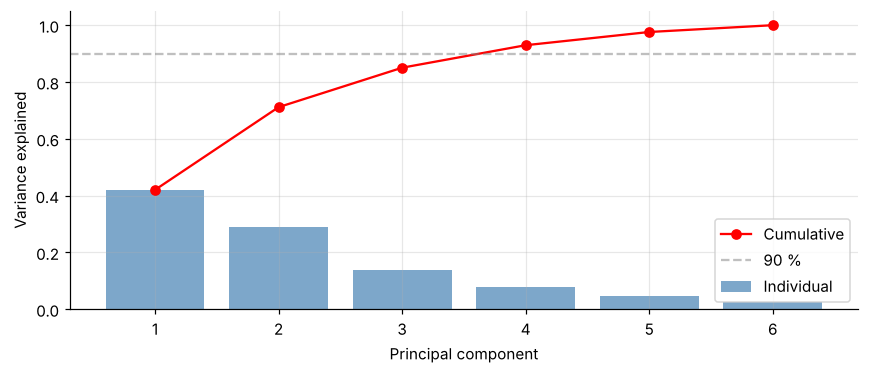

Cumulative variance: [0.42  0.711 0.85  0.93  0.976 1.   ]


In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_drivers[FEATURE_COLS])
pca_full = PCA(n_components=len(FEATURE_COLS)).fit(X_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(1, 7), pca_full.explained_variance_ratio_, alpha=0.7, color="steelblue", label="Individual")
ax.plot(range(1, 7), cumvar, "ro-", label="Cumulative")
ax.axhline(0.9, color="gray", ls="--", alpha=0.5, label="90 %")
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained"); ax.legend()
plt.tight_layout(); plt.show()
print("Cumulative variance:", np.round(cumvar, 3))

## Step 5 — Choose K with the Elbow Method

K-Means requires the number of clusters upfront. We don't know K —
so we run K-Means for K=2 to 8 and plot **inertia** (sum of squared
distances from each point to its cluster center).

Inertia always drops as K increases. The "elbow" is where the curve
bends and gains flatten out — adding more clusters stops being meaningful.
That bend is our K.

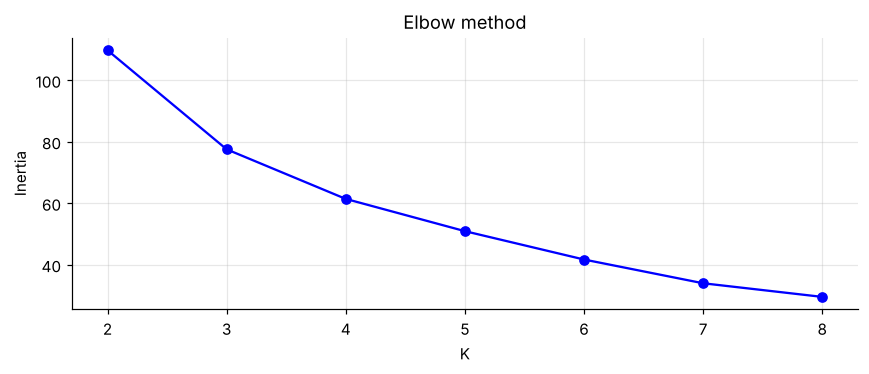

{2: 109.7, 3: 77.5, 4: 61.4, 5: 50.9, 6: 41.7, 7: 34.0, 8: 29.5}


In [13]:
K_range = range(2, 9)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_ for k in K_range]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(K_range, inertias, "bo-"); ax.set_xlabel("K"); ax.set_ylabel("Inertia")
ax.set_title("Elbow method"); plt.tight_layout(); plt.show()
print({k: round(v, 1) for k, v in zip(K_range, inertias)})

## Step 6 — K-Means (K=4), V1 features first

K=4 as in V2 (the elbow and four recognisable archetypes). We cluster in the scaled feature space, not in PCA —
PCA is only for plotting. First with all six features, including DRS, to re-check the V1 → V2 story.

In [14]:
def show_clusters(labels, frame):
    for c in sorted(set(labels)):
        g = frame[labels == c]
        print(f"Cluster {c} ({len(g)}): " + ", ".join(f"{d} ({t})" for d, t in zip(g.Driver, g.Team)))

km_v1 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
show_clusters(km_v1.labels_, df_drivers)
print("\nMean drs_usage_pct by team:")
print(df_all.groupby("Team").drs_usage_pct.mean().sort_values().round(3).to_string())

Cluster 0 (8): ALB (Williams), ANT (Mercedes), BEA (Haas F1 Team), DOO (Alpine), HAM (Ferrari), LEC (Ferrari), OCO (Haas F1 Team), SAI (Williams)
Cluster 1 (3): COL (Alpine), SAR (Williams), ZHO (Kick Sauber)
Cluster 2 (7): GAS (Alpine), HAD (Racing Bulls), NOR (McLaren), PIA (McLaren), RIC (RB), RUS (Mercedes), TSU (Red Bull Racing)
Cluster 3 (9): ALO (Aston Martin), BOR (Kick Sauber), BOT (Kick Sauber), HUL (Kick Sauber), LAW (Racing Bulls), MAG (Haas F1 Team), PER (Red Bull Racing), STR (Aston Martin), VER (Red Bull Racing)

Mean drs_usage_pct by team:
Team
Racing Bulls       0.264
Haas F1 Team       0.265
Kick Sauber        0.265
Mercedes           0.267
RB                 0.267
Red Bull Racing    0.269
Aston Martin       0.269
Alpine             0.270
Williams           0.271
McLaren            0.272
Ferrari            0.272


**V1 re-checked on clean data.** With all six features (DRS included) there is no one-driver cluster here, and DRS
usage is the same for every team (0.26–0.27 of the lap): the corrupted McLaren DRS channel that isolated Norris in
V1 is not in these sessions. DRS stays out anyway — how long the flap is open is set by the DRS zones and the
one-second rule, not by the driver's style. The V2 story below is kept as it happened.

## Clustering V1 → Problem → V2

**V2 (original run) — V1 result:** Norris isolated into his own cluster (Cluster 3, 1 driver).
A cluster of 1 is always a red flag — not a real pattern.

**Root cause:** `drs_usage_pct = 0.000` for NOR across all 10 circuits.
FastF1 DRS channel corrupted for McLaren. K-Means saw him as an extreme
outlier on that feature and separated him completely.

**Fix:** Remove `drs_usage_pct` from features. DRS in the Race Simulator
(Module 4) is a race rule, not a learned feature — so this removal has
zero impact on downstream modules.

**Lesson:** Always inspect cluster assignments. If one cluster has
1 driver, something is wrong with the data, not the driver.

In [15]:
FEATURE_COLS_CLEAN = ["brake_application_pct", "full_throttle_pct", "coasting_pct", "throttle_smoothness",
                      "min_speed_ratio"]
scaler_clean = StandardScaler()
X_clean = scaler_clean.fit_transform(df_drivers[FEATURE_COLS_CLEAN])
kmeans_clean = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_clean)
df_drivers["Cluster"] = kmeans_clean.labels_
show_clusters(kmeans_clean.labels_, df_drivers)

# Name each cluster by what sets it apart: its two most extreme features (z-scores of the centre)
LABEL = {"brake_application_pct": "brake", "full_throttle_pct": "full throttle", "coasting_pct": "coasting",
         "throttle_smoothness": "throttle aggression", "min_speed_ratio": "corner speed"}
centres = pd.DataFrame(kmeans_clean.cluster_centers_, columns=FEATURE_COLS_CLEAN)
CLUSTER_NAMES = {}
for c, row in centres.iterrows():
    top = row.abs().sort_values(ascending=False).index[:2]
    CLUSTER_NAMES[c] = " · ".join(f"{'high' if row[f] > 0 else 'low'} {LABEL[f]}" for f in top)
print("\nCluster centres (z-scores):")
print(centres.round(2).assign(name=pd.Series(CLUSTER_NAMES)).to_string())

Cluster 0 (8): ALB (Williams), ANT (Mercedes), BEA (Haas F1 Team), DOO (Alpine), HAM (Ferrari), LEC (Ferrari), OCO (Haas F1 Team), SAI (Williams)
Cluster 1 (10): ALO (Aston Martin), BOR (Kick Sauber), BOT (Kick Sauber), HUL (Kick Sauber), LAW (Racing Bulls), MAG (Haas F1 Team), PER (Red Bull Racing), STR (Aston Martin), VER (Red Bull Racing), ZHO (Kick Sauber)
Cluster 2 (7): GAS (Alpine), HAD (Racing Bulls), NOR (McLaren), PIA (McLaren), RIC (RB), RUS (Mercedes), TSU (Red Bull Racing)
Cluster 3 (2): COL (Alpine), SAR (Williams)

Cluster centres (z-scores):
   brake_application_pct  full_throttle_pct  coasting_pct  throttle_smoothness  min_speed_ratio                                           name
0                   0.57              -0.28         -1.18                -1.28             0.36         low throttle aggression · low coasting
1                   0.14               0.50          0.20                 1.00            -0.20  high throttle aggression · high full throttle
2       

## Step 7 — UMAP Visualization

UMAP (Uniform Manifold Approximation and Projection) finds the
best 2D layout of the data that keeps similar drivers close together.

Unlike PCA (linear), UMAP captures non-linear relationships —
drivers who are similar in complex combinations of features end up
near each other even if no single feature separates them cleanly.

We ran PCA to 4D first , then UMAP on those 4
clean dimensions. This is more stable than UMAP on raw features.

PCA 4D keeps 97.0% of the variance


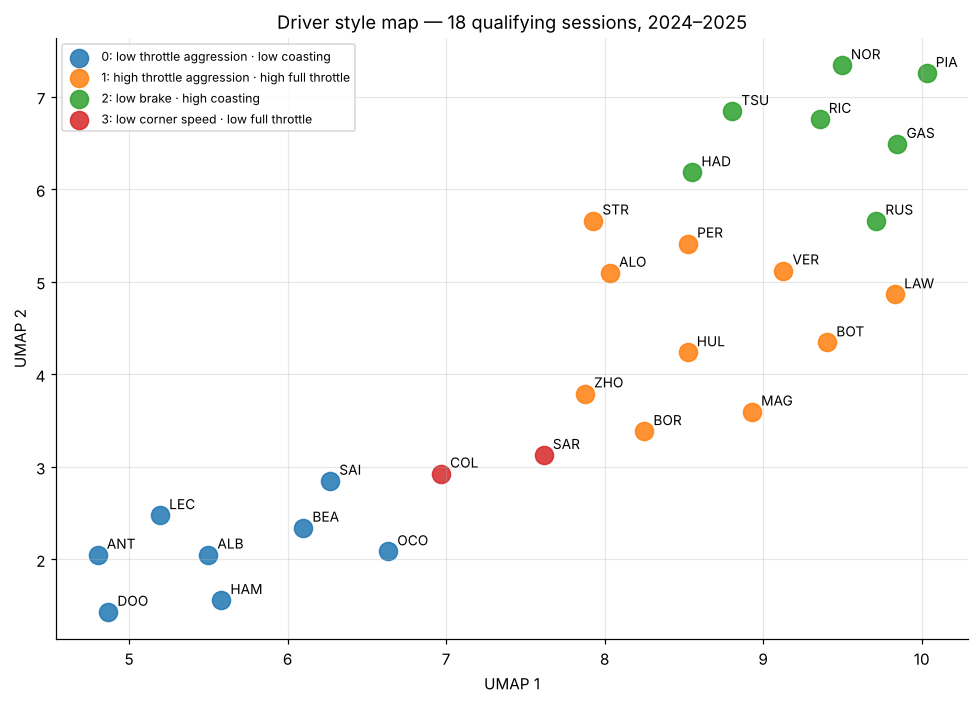

In [16]:
pca_4d = PCA(n_components=4, random_state=42)
X_pca4 = pca_4d.fit_transform(X_clean)
print(f"PCA 4D keeps {pca_4d.explained_variance_ratio_.sum():.1%} of the variance")
X_umap = umap.UMAP(n_components=2, random_state=42, n_neighbors=8, min_dist=0.3).fit_transform(X_pca4)
df_drivers["UMAP1"], df_drivers["UMAP2"] = X_umap[:, 0], X_umap[:, 1]

COLOURS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
fig, ax = plt.subplots(figsize=(9, 6.5))
for c in sorted(df_drivers.Cluster.unique()):
    g = df_drivers[df_drivers.Cluster == c]
    ax.scatter(g.UMAP1, g.UMAP2, s=140, color=COLOURS[c], alpha=0.85, label=f"{c}: {CLUSTER_NAMES[c]}")
    for _, r in g.iterrows():
        ax.annotate(r.Driver, (r.UMAP1, r.UMAP2), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
ax.set_title(f"Driver style map — {len(all_features)} qualifying sessions, 2024–2025")
ax.legend(fontsize=8, loc="best"); plt.tight_layout(); plt.show()

## Reading the UMAP Plot

The axes have no literal meaning — UMAP Dimension 1 and 2 are not
interpretable numbers. What matters is **distance between points**:
drivers close together have similar styles, drivers far apart are different.


**Key findings (V3: 18 correctly labelled sessions, clean channels):**

- **HAM + LEC are neighbours again** (smoothest throttle, almost no coasting), with SAI, ALB, ANT, BEA, DOO and OCO
  — the most stable result across V2 and V3.
- **VER sits with PER, ALO and STR in the committed-throttle group** (most full throttle, most aggressive throttle
  changes).
- **NOR + PIA are no longer a cluster of their own.** On clean data they join RUS, GAS, TSU, HAD and RIC (least
  braking, most coasting). They are still at the edge of the map, so a McLaren signature is real — but V2 made it
  look more unique than it is, partly through NOR's 98 % throttle ceiling.
- **COL + SAR form a two-driver group** (lowest corner-speed ratio): two rookies in slower cars. As V1 taught, a
  cluster this small is a warning sign — it may be car and experience more than style.
- **The car shows through:** team-mates often share a cluster (Ferrari, McLaren, Aston Martin, Sauber), but not
  always (Mercedes: RUS / ANT; Red Bull: VER / TSU).

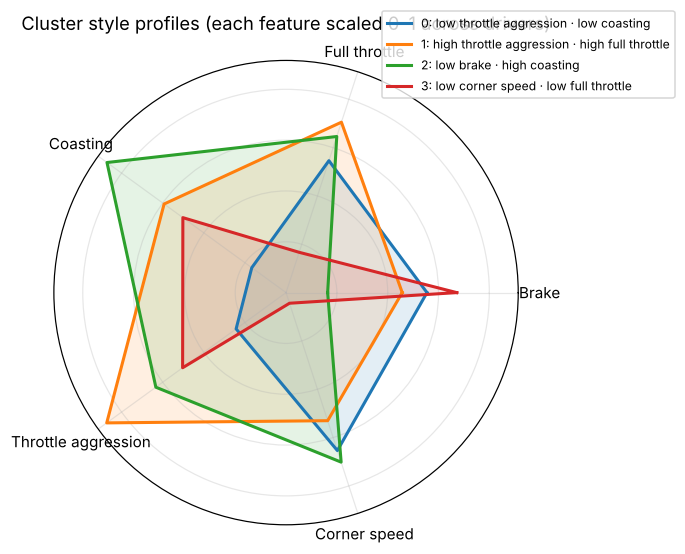

In [17]:
labels = [LABEL[f].capitalize() for f in FEATURE_COLS_CLEAN]
norm = (df_drivers[FEATURE_COLS_CLEAN] - df_drivers[FEATURE_COLS_CLEAN].min()) / (
        df_drivers[FEATURE_COLS_CLEAN].max() - df_drivers[FEATURE_COLS_CLEAN].min())
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist() + [0]
fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={"polar": True})
for c in sorted(df_drivers.Cluster.unique()):
    vals = norm[df_drivers.Cluster == c].mean().tolist()
    ax.plot(angles, vals + vals[:1], color=COLOURS[c], lw=2, label=f"{c}: {CLUSTER_NAMES[c]}")
    ax.fill(angles, vals + vals[:1], color=COLOURS[c], alpha=0.12)
ax.set_xticks(angles[:-1], labels); ax.set_yticklabels([])
ax.set_title("Cluster style profiles (each feature scaled 0–1 across drivers)", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.12), fontsize=8)
plt.tight_layout(); plt.show()

## How to read this radar chart

Each spoke = one feature. Further out = higher value relative to all drivers.
Color = cluster. Shapes overlap because no cluster is extreme on every feature —
driving style is a combination, not a single dimension.


**Reading it.** Cluster 0 (smooth precision) is defined by what it doesn't do: the least coasting and the smoothest
throttle. Cluster 1 (committed throttle) has the most full throttle and the most aggressive throttle changes.
Cluster 2 brakes least and coasts most. Cluster 3, the two rookies, has by far the lowest corner-speed ratio.

## Known limitations

- **Car confound.** A qualifying lap is the driver *and* the car: team-mates share a car, so clusters that look like
  teams may be car signatures. Mitigated by using driver-controlled inputs (throttle, brake), not eliminated.
- **Brake is on/off** in FastF1, so we measure *when* drivers brake, not *how hard*.
- **No `nGear` / `RPM` features yet** — shift points are a known style marker, but with ~20 drivers they would
  likely overfit (Future Iterations).
- **Small sample:** ~20 drivers, one lap per session. Cluster membership of drivers near a boundary can change with
  one more session.